# 1.0 Contexto

Neste notebook são implementadas e comparadas duas políticas de decisão de canal de contato: uma alocação uniforme, equivalente a um teste A/B tradicional, e uma política adaptativa baseada em Thompson Sampling.

A base utilizada é a camada _trusted_ produzida na análise exploratória, na
qual foram removidas as linhas com `contact` = _unknown_ (ausência de
registro), removida a coluna `duration` por vazamento temporal, decomposta a coluna `pdays` em `contatado_antes` e `dias_ultimo_contato`, e renomeada a categoria _unknown_ de `poutcome` para `sem_campanha_anterior`.

A avaliação é feita por _replay_: os clientes são percorridos em ordem aleatória e, a cada rodada, a política escolhe um canal. Quando a escolha coincide com o canal efetivamente utilizado no registro histórico, o resultado real é observado e incorporado ao aprendizado. Quando não coincide, a rodada é descartada, pois o resultado contrafactual não existe na base.

# 2.0 Setup e Carga

In [1]:
# Importando bibliotecas necessárias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Carregando data set
df_trusted = pd.read_parquet('../data/trusted/bank_clean.parquet')

# Apenas o necessário para a simulação

dados = df_trusted[['contact', 'y']].copy()
dados['contact'] = dados ['contact'].astype(str)

print(dados['contact'].value_counts())
print(dados.groupby('contact')['y'].mean())

contact
cellular     29285
telephone     2906
Name: count, dtype: int64
contact
cellular     0.149189
telephone    0.134205
Name: y, dtype: float64


# 3.0 Preparação do ambiente de simulação

In [3]:
# Criação da Função Replay

ARMS = ['cellular', 'telephone']


def replay(dados, politica, seed, n_rodadas=20000):
    """
    A cada rodada a política escolhe um braço e observa o resultado de um
    cliente real sorteado do histórico daquele braço.
    """
    rng = np.random.default_rng(seed)

    # Histórico real de cada braço
    pools = {arm: dados.loc[dados['contact'] == arm, 'y'].values
             for arm in ARMS}

    politica.reset()
    recompensas = np.empty(n_rodadas, dtype=int)
    escolhas = np.empty(n_rodadas, dtype=object)

    for i in range(n_rodadas):
        arm = politica.escolher(rng)
        pool = pools[arm]
        resultado = pool[rng.integers(len(pool))]

        politica.atualizar(arm, resultado)
        recompensas[i] = resultado
        escolhas[i] = arm

    return recompensas, escolhas
                            

# 4.0 Baseline - alocação uniforme

Elaboração do baseline: Teste A/B que dá 50% de chance para cada canal.

In [4]:
class Uniforme:
    """Alocação 50/50. Não aprende."""

    def reset(self):
        pass

    def escolher(self, rng):
        return ARMS[rng.integers(len(ARMS))]
    
    def atualizar(self, braco, recompensa):
        pass

In [5]:
N_REPS = 30

def rodar (politica, n_reps=N_REPS):
    resultado = []
    for seed in range(n_reps):
        recompensas, escolhas = replay(dados, politica, seed)
        resultado.append({'recompensas': recompensas, 'escolhas': escolhas})
    return resultado

res_uniforme = rodar(Uniforme())

# Resumo

taxas = [r['recompensas'].mean() for r in res_uniforme]
n_rodadas = [len(r['recompensas']) for r in res_uniforme]

print(f"Taxa de conversão média: {np.mean(taxas): .4f}")
print(f"Rodadas aproveitadas (média): {np.mean(n_rodadas):.0f}")

Taxa de conversão média:  0.1417
Rodadas aproveitadas (média): 20000


# 5.0 Thompson Sampling

In [6]:
class ThompsonSampling:
    """
    Mantém uma distribuição Beta por braço. A cada rodada sorteia um valor
    de cada distribuição e escolhe o braço com o maior sorteio.
    """

    def __init__(self, arms=ARMS):
        self.arms = arms
        self.reset()

    def reset(self):
        self.alfa = {arm: 1 for arm in self.arms}   # conversões + 1
        self.beta = {arm: 1 for arm in self.arms}   # não conversões + 1

    def escolher(self, rng):
        sorteios = {arm: rng.beta(self.alfa[arm], self.beta[arm])
                    for arm in self.arms}
        return max(sorteios, key=sorteios.get)

    def atualizar(self, braco, recompensa):
        if recompensa == 1:
            self.alfa[braco] += 1
        else:
            self.beta[braco] += 1

In [7]:
res_thompson = rodar(ThompsonSampling())

taxas_ts = [r['recompensas'].mean() for r in res_thompson]
print(f"Taxa de conversão média: {np.mean(taxas_ts):.4f}")

# Proporção de vezes que cada braço foi escolhido
prop = {arm: np.mean([(r['escolhas'] == arm).mean() for r in res_thompson])
        for arm in ARMS}
print(prop)

Taxa de conversão média: 0.1467
{'cellular': np.float64(0.8708083333333333), 'telephone': np.float64(0.12919166666666668)}


In [ ]:
# Consolidação do resultado

resumo = pd.DataFrame({
    'politica': ['Uniforme (A/B 50/50)', 'Thompson Sampling'],
    'conversao': [np.mean(taxas), np.mean(taxas_ts)],
    'desvio':    [np.std(taxas),  np.std(taxas_ts)],
    'prop_cellular': [0.5, prop['cellular']],
})
resumo['ganho_pp'] = (resumo['conversao'] - resumo['conversao'][0]) * 100
resumo.round(4)

,politica,conversao,desvio,prop_cellular,ganho_pp
0,Uniforme (A/B 50/50),0.1417,0.0022,0.5000,0.000
1,Thompson Sampling,0.1467,0.0025,0.8708,0.498


# 6.0 Comparação

## 6.1 Conversão acumulada - baseline vs adaptativo

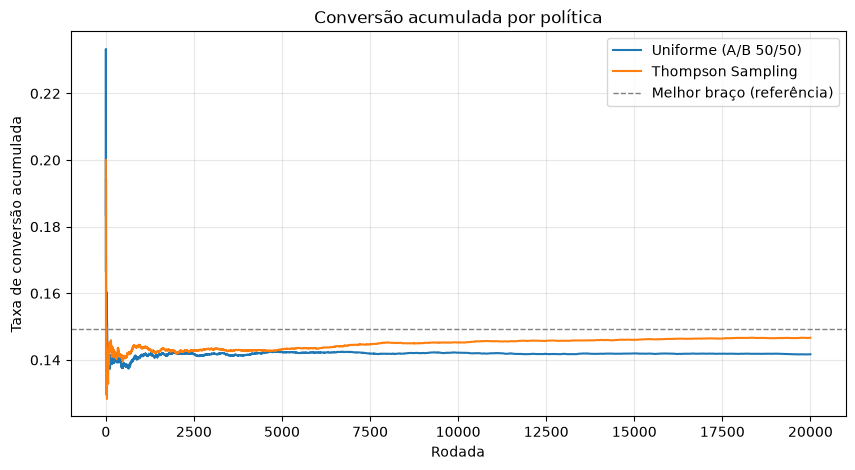

In [9]:
# Comparação gráfica de baseline vs adaptativo

def curva_acumulada(resultados):
    """Média das curvas de conversão acumulada das repetições."""
    curvas = [np.cumsum(r['recompensas']) / np.arange(1, len(r['recompensas']) + 1)
              for r in resultados]
    return np.mean(curvas, axis=0)

curva_unif = curva_acumulada(res_uniforme)
curva_ts   = curva_acumulada(res_thompson)

plt.figure(figsize=(10, 5))
plt.plot(curva_unif, label='Uniforme (A/B 50/50)')
plt.plot(curva_ts,   label='Thompson Sampling')
plt.axhline(0.1492, ls='--', c='gray', lw=1, label='Melhor braço (referência)')
plt.xlabel('Rodada')
plt.ylabel('Taxa de conversão acumulada')
plt.title('Conversão acumulada por política')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6.2 Evolução da escolha dos braços ao longo do tempo

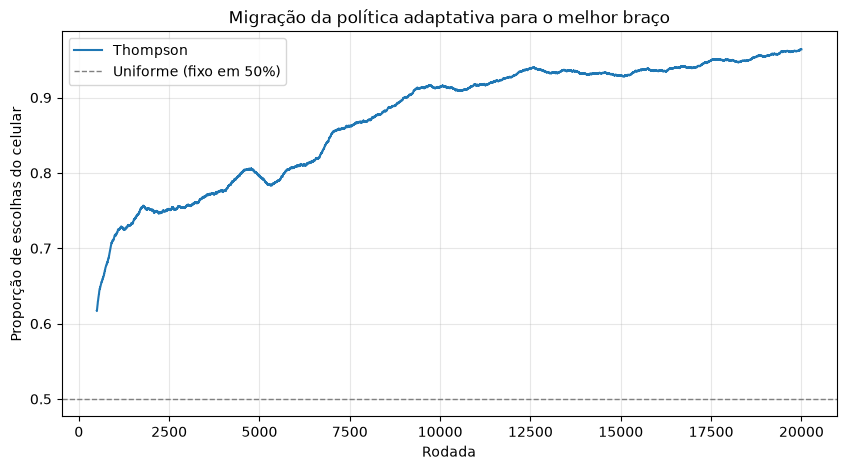

In [10]:
#Evolução do Thompson Sampling ao longo das rodadas comparado com baseline

def curva_braco(resultados, arm, janela=500):
    """Proporção de escolhas do braço, em média móvel."""
    series = [pd.Series(r['escolhas'] == arm).rolling(janela).mean()
              for r in resultados]
    return np.mean(series, axis=0)

plt.figure(figsize=(10, 5))
plt.plot(curva_braco(res_thompson, 'cellular'), label='Thompson')
plt.axhline(0.5, ls='--', c='gray', lw=1, label='Uniforme (fixo em 50%)')
plt.xlabel('Rodada')
plt.ylabel('Proporção de escolhas do celular')
plt.title('Migração da política adaptativa para o melhor braço')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6.3 Conclusão

A política adaptativa atinge conversão de 14,67% contra 14,17% da alocação uniforme, um ganho de 0,50 ponto percentual. O desvio padrão entre as 30 repetições é de 0,25 pp, metade do ganho observado, o que indica resultado estável e não decorrente de variação aleatória.

O primeiro gráfico mostra que a alocação uniforme estabiliza em torno de 14,2% e permanece ali, enquanto o Thompson Sampling converge progressivamente em direção à taxa do melhor braço (14,92%).

O segundo gráfico evidencia o mecanismo: partindo sem informação prévia, a política eleva a proporção de escolhas do celular de 50% para 96% ao longo da simulação, sem que essa informação tenha sido fornecida ao modelo. A exploração se reduz automaticamente à medida que a incerteza sobre cada braço diminui.

A diferença entre as políticas é o tráfego desperdiçado. O teste A/B mantém metade dos contatos no canal inferior durante toda a sua duração; a política adaptativa reduz essa parcela de forma contínua. Em 20.000 contatos simulados, o ganho corresponde a aproximadamente 100 conversões adicionais.

A simulação utiliza 20.000 rodadas com amostragem com reposição do histórico real de cada braço, repetida 30 vezes com sementes distintas.

# 7.0 Golden Set

In [11]:
# Política treinada com todo o histórico disponível
politica_final = ThompsonSampling()
replay(dados, politica_final, seed=0)

print("Estado aprendido:")
for arm in ARMS:
    a, b = politica_final.alfa[arm], politica_final.beta[arm]
    print(f"  {arm}: alfa={a}, beta={b}, taxa estimada={a/(a+b):.4f}")

Estado aprendido:
  cellular: alfa=2732, beta=15969, taxa estimada=0.1461
  telephone: alfa=163, beta=1140, taxa estimada=0.1251


In [12]:
rng = np.random.default_rng(42)

clientes = df_trusted.sample(5, random_state=42)

recomendacoes = []
for _, cli in clientes.iterrows():
    arm = politica_final.escolher(rng)
    recomendacoes.append({
        'idade': cli['age'],
        'profissao': cli['job'],
        'estado_civil': cli['marital'],
        'saldo': cli['balance'],
        'canal_recomendado': arm,
        'canal_historico': cli['contact'],
        'converteu_no_historico': cli['y'],
    })

pd.DataFrame(recomendacoes)

,idade,profissao,estado_civil,saldo,canal_recomendado,canal_historico,converteu_no_historico
0,35,student,single,0,cellular,telephone,0
1,50,technician,married,232,cellular,cellular,0
2,47,management,married,1675,cellular,cellular,0
3,34,services,married,2956,cellular,cellular,1
4,31,entrepreneur,married,162,cellular,cellular,0


Cinco clientes selecionados aleatoriamente da base, com a recomendação de canal produzida pela política treinada sobre o histórico completo.

**Estado aprendido pela política**

| Braço | α | β | Taxa estimada | Taxa real |
|---|---|---|---|---|
| cellular | 2.732 | 15.969 | 14,61% | 14,92% |
| telephone | 163 | 1.140 | 12,51% | 13,42% |

A política convergiu para estimativas próximas das taxas reais sem que estas tenham sido informadas. A diferença no volume de observações entre os braços (18.701 contra 1.303) reflete a redução progressiva da exploração: o braço inferior deixa de ser testado à medida que a incerteza sobre ele diminui.

**Recomendações**

Os cinco casos receberam recomendação de celular. O resultado é coerente com a política aprendida: como o celular apresenta taxa superior e a incerteza sobre ambos os braços já é baixa, a probabilidade de o sorteio favorecer o telefone é pequena — aproximadamente 13% conforme a proporção observada na simulação.

Cabe registrar uma característica do modelo adotado: por se tratar de um bandit não contextual, a recomendação não depende das características do cliente. A variação entre casos decorre do sorteio das distribuições Beta, não do perfil. Essa escolha foi justificada na análise exploratória, que não identificou segmento em que o telefone superasse o celular de forma 
sustentada — condição necessária para que um modelo contextual tivesse o que aprender.

No caso 0, a recomendação diverge do canal efetivamente utilizado no histórico (telefone), que não resultou em conversão. Os demais coincidem com o histórico.

# 8.0 Registro no MLflow

In [17]:
import mlflow
from pathlib import Path

db = Path('../mlflow.db').resolve()
mlflow.set_tracking_uri(f'sqlite:///{db}')

mlflow.set_experiment('datathon-bandit-canal')

# Baseline
with mlflow.start_run(run_name='uniforme_50_50'):
    mlflow.log_params({
        'politica': 'uniforme',
        'n_rodadas': 20000,
        'n_repeticoes': N_REPS,
        'arms': ','.join(ARMS),
    })
    mlflow.log_metrics({
        'conversao_media': float(np.mean(taxas)),
        'conversao_desvio': float(np.std(taxas)),
        'prop_cellular': 0.5,
    })

# Adaptativo
with mlflow.start_run(run_name='thompson_sampling'):
    mlflow.log_params({
        'politica': 'thompson_sampling',
        'prior_alfa': 1,
        'prior_beta': 1,
        'n_rodadas': 20000,
        'n_repeticoes': N_REPS,
        'arms': ','.join(ARMS),
    })
    mlflow.log_metrics({
        'conversao_media': float(np.mean(taxas_ts)),
        'conversao_desvio': float(np.std(taxas_ts)),
        'prop_cellular': float(prop['cellular']),
        'ganho_pp': float((np.mean(taxas_ts) - np.mean(taxas)) * 100),
    })